# Placebo test: does the method find a "euro effect" where there was no euro?

The event study (`sql/05`, `sql/07`, and the Power BI report) estimates how much faster prices rose in the
first year of the euro than in a control, after removing the pre-existing trend. For services in Croatia
that is **+1.8 index points against the euro area** and **+0.3 against the non-euro peers**.

But how big is "big"? Any method applied to noisy monthly data produces *some* number. A placebo test measures
that noise directly: **run exactly the same calculation for fake adoption dates**, when nothing special happened,
and see what the method reports.

- If fake dates give numbers near zero and the real date stands out, the effect is real.
- If fake dates give numbers just as large, the real estimate is within the noise.

**Design**
- Fake dates: every month from 18 to 240 months before the real adoption, as far back as the data allows
  (controls' services indices start in 1999-2000). The 18-month gap keeps the fake "year after adoption"
  clear of the six months before the real changeover, when prices were already shown in euros.
- Same settings as the headline numbers: 24-month trend window, step = first year after vs the year before.
- p-value = share of fake dates whose step is at least as large as the real one (one-sided, since the
  question is whether the euro raised prices).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from event_study import empirical_p, load_index, placebo_steps, step_effect  # noqa: E402
from load_sql import connect  # noqa: E402

ADOPTION = {"SI": "2007-01-01", "SK": "2009-01-01", "EE": "2011-01-01",
            "LV": "2014-01-01", "LT": "2015-01-01", "HR": "2023-01-01"}
ADOPTION = {k: pd.Timestamp(v) for k, v in ADOPTION.items()}
NAMES = {"SI": "Slovenia", "SK": "Slovakia", "EE": "Estonia", "LV": "Latvia", "LT": "Lithuania",
         "HR": "Croatia", "EA19": "euro area", "PEERS": "non-euro peers"}
CONTROLS = ["EA19", "PEERS"]
CATEGORIES = {"SERV": "Services", "GD": "Goods", "TOTAL": "All items"}
ORANGE, GREY = "#E66C37", "#A19F9D"

conn = connect("EuroPrices")
idx = load_index(conn, list(ADOPTION) + ["EA19", "HU", "PL", "CZ", "RO"], list(CATEGORIES))
print(f"{idx.shape[1]} series, {idx.index.min():%Y-%m} to {idx.index.max():%Y-%m}")

33 series, 1996-01 to 2026-08


## 1. Check: Python reproduces the SQL views

The placebo test reimplements the event study in Python (`src/event_study.py`). For the real adoption dates it
must give the same numbers as the SQL views the report uses.

In [2]:
sql = '''
SELECT country_code, control_code, coicop_code,
       AVG(CASE WHEN event_month BETWEEN 0 AND 11 THEN excess - pre_slope_24 * (event_month + 1) END)
     - AVG(CASE WHEN event_month BETWEEN -12 AND -1 THEN excess - pre_slope_24 * (event_month + 1) END)
FROM pbi.event_study_detrended
WHERE coicop_code IN ('SERV', 'GD', 'TOTAL') AND control_code IN ('EA19', 'PEERS') AND country_code <> 'BG'
GROUP BY country_code, control_code, coicop_code
'''
check = pd.DataFrame([tuple(r) for r in conn.cursor().execute(sql).fetchall()],
                     columns=["adopter", "control", "coicop", "sql"])
check["sql"] = check["sql"].astype(float)
check["python"] = [step_effect(idx, r.adopter, r.control, r.coicop, ADOPTION[r.adopter])
                   for r in check.itertuples()]
print(f"{len(check)} estimates, largest difference: {(check.sql - check.python).abs().max():.2e}")

36 estimates, largest difference: 1.13e-14


## 2. Croatia, services

Each dot is the "euro effect" the method reports if the euro had been introduced on that (fake) date.
The orange line is the real estimate.

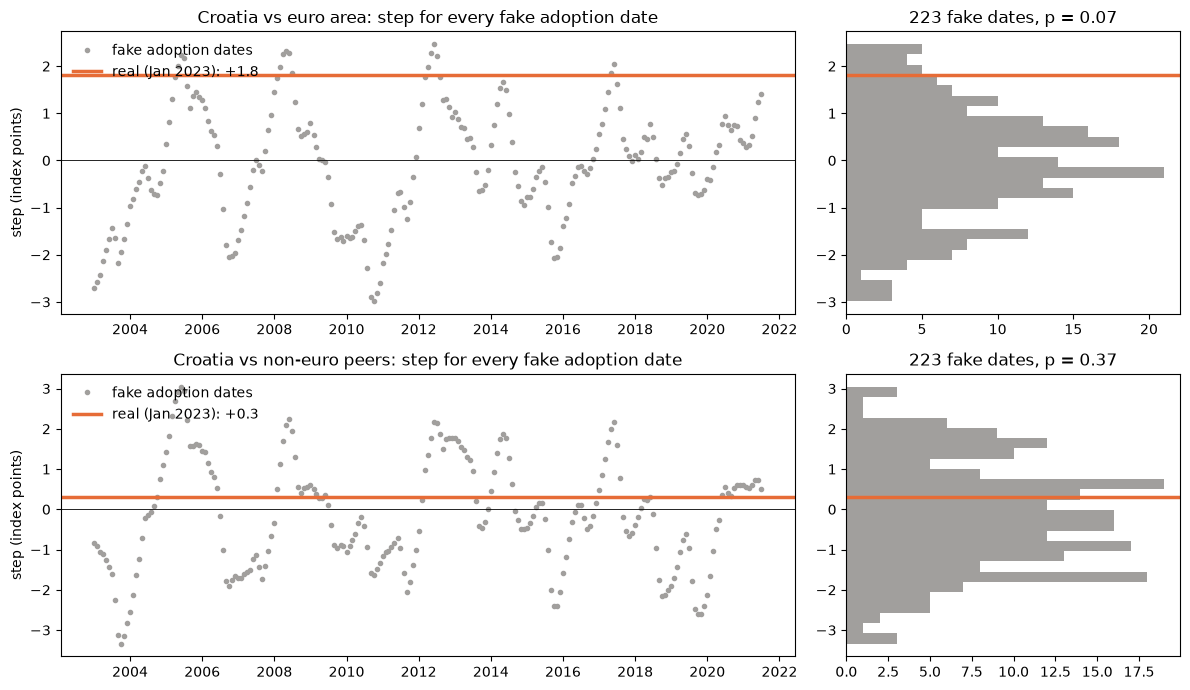

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), gridspec_kw={"width_ratios": [2.2, 1]})
for row, control in enumerate(CONTROLS):
    real = step_effect(idx, "HR", control, "SERV", ADOPTION["HR"])
    pl = placebo_steps(idx, "HR", ADOPTION["HR"], control, "SERV")
    p = empirical_p(real, pl["step"])

    ax = axes[row, 0]
    ax.plot(pl["fake_date"], pl["step"], "o", ms=3, color=GREY, label="fake adoption dates")
    ax.axhline(real, color=ORANGE, lw=2.5, label=f"real (Jan 2023): {real:+.1f}")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"Croatia vs {NAMES[control]}: step for every fake adoption date")
    ax.set_ylabel("step (index points)")
    ax.legend(loc="upper left", frameon=False)

    ax = axes[row, 1]
    ax.hist(pl["step"], bins=25, color=GREY, orientation="horizontal")
    ax.axhline(real, color=ORANGE, lw=2.5)
    ax.set_title(f"{len(pl)} fake dates, p = {p:.2f}")
    ax.sharey(axes[row, 0])
fig.tight_layout()
plt.show()

In [4]:
for control in CONTROLS:
    pl = placebo_steps(idx, "HR", ADOPTION["HR"], control, "SERV")
    top = pl.reindex(pl["step"].abs().sort_values(ascending=False).index).head(5)
    print(f"vs {NAMES[control]}: {(pl['step'].abs() <= 2).mean():.0%} of fake steps within ±2; largest at",
          ", ".join(f"{d:%Y-%m} ({s:+.1f})" for d, s in zip(top.fake_date, top.step)))

vs euro area: 89% of fake steps within ±2; largest at 2010-10 (-3.0), 2010-09 (-2.9), 2010-11 (-2.8), 2003-01 (-2.7), 2010-12 (-2.6)


vs non-euro peers: 86% of fake steps within ±2; largest at 2003-10 (-3.3), 2003-11 (-3.2), 2003-09 (-3.1), 2005-06 (+3.0), 2005-07 (+2.9)


The fake effects for Croatia mostly stay within ±2 points (86-89% of them); the largest, around ±3,
come from fake dates in 2003, 2005 and late 2010. Against the euro area the real +1.8 is larger than all but
~7% of fake dates (p ≈ 0.07): close to, but not below, the usual 5% threshold. Against the non-euro peers the
real +0.3 is well inside the noise.

## 3. Every adopter

Same test for each adopter, control and category. `p5`-`p95` is the range that holds 90% of the fake estimates.

In [5]:
rows = []
for cat in ["SERV", "GD"]:
    for control in CONTROLS:
        for adopter, date in ADOPTION.items():
            real = step_effect(idx, adopter, control, cat, date)
            pl = placebo_steps(idx, adopter, date, control, cat)["step"]
            rows.append({"category": CATEGORIES[cat], "control": NAMES[control], "adopter": NAMES[adopter],
                         "real": real, "fake dates": len(pl), "p5": pl.quantile(0.05),
                         "median": pl.median(), "p95": pl.quantile(0.95), "p": empirical_p(real, pl)})
by_adopter = pd.DataFrame(rows)
by_adopter.style.format({"real": "{:+.1f}", "p5": "{:+.1f}", "median": "{:+.1f}", "p95": "{:+.1f}",
                         "p": "{:.2f}"}).hide(axis="index")

category,control,adopter,real,fake dates,p5,median,p95,p
Services,euro area,Slovenia,+0.9,38,-2.4,-1.2,-0.4,0.03
Services,euro area,Slovakia,+0.5,74,-3.7,-1.3,+3.6,0.24
Services,euro area,Estonia,+2.4,86,-6.6,+0.6,+4.0,0.22
Services,euro area,Latvia,+2.5,134,-10.3,+1.5,+6.0,0.33
Services,euro area,Lithuania,+1.2,146,-6.8,+0.8,+4.5,0.48
Services,euro area,Croatia,+1.8,223,-2.1,-0.1,+2.0,0.07
Services,non-euro peers,Slovenia,+0.9,38,-2.7,-0.8,+1.7,0.21
Services,non-euro peers,Slovakia,+0.4,62,-2.1,-1.0,+5.4,0.29
Services,non-euro peers,Estonia,+3.4,86,-6.5,+1.5,+3.8,0.14
Services,non-euro peers,Latvia,+2.6,122,-10.1,+2.2,+5.3,0.41


One country at a time, the test is weak: for most adopters the real step sits inside the range of fake
ones. The fake estimates are very wide for the Baltic states (e.g. Latvia −10 to +6), whose placebo windows run
through the 2008-10 crisis, when their prices swung far more than the euro area's.

## 4. All six adoptions together

A single country's estimate is noisy, but the noise is different in every country while a genuine changeover
effect should push all of them the same way. So the stronger test is on the **average** step across the six
adoptions: draw one fake date per adopter at random, average the six fake steps, repeat 10,000 times, and compare
the real average with that distribution.

In [6]:
rng = np.random.default_rng(2023)
pooled, draws_for_plot = [], {}
for cat in CATEGORIES:
    for control in CONTROLS:
        real = np.mean([step_effect(idx, a, control, cat, d) for a, d in ADOPTION.items()])
        fake = [placebo_steps(idx, a, d, control, cat)["step"].to_numpy() for a, d in ADOPTION.items()]
        draws = np.mean([rng.choice(f, 10_000) for f in fake], axis=0)
        draws_for_plot[(cat, control)] = (real, draws)
        pooled.append({"category": CATEGORIES[cat], "control": NAMES[control], "real average": real,
                       "fake p5": np.percentile(draws, 5), "fake median": np.median(draws),
                       "fake p95": np.percentile(draws, 95), "p": (1 + (draws >= real).sum()) / (1 + len(draws))})
pooled = pd.DataFrame(pooled)
pooled.style.format({c: "{:+.2f}" for c in ["real average", "fake p5", "fake median", "fake p95"]}
                    | {"p": "{:.3f}"}).hide(axis="index")

category,control,real average,fake p5,fake median,fake p95,p
Services,euro area,+1.54,-2.31,-0.14,+1.36,0.030
Services,non-euro peers,+1.50,-2.01,+0.22,+1.84,0.096
Goods,euro area,+0.91,-1.74,-0.14,+1.28,0.117
Goods,non-euro peers,-0.48,-1.79,+0.09,+1.71,0.694
All items,euro area,+0.86,-1.82,-0.17,+1.38,0.141
All items,non-euro peers,+0.13,-1.96,-0.04,+1.55,0.436


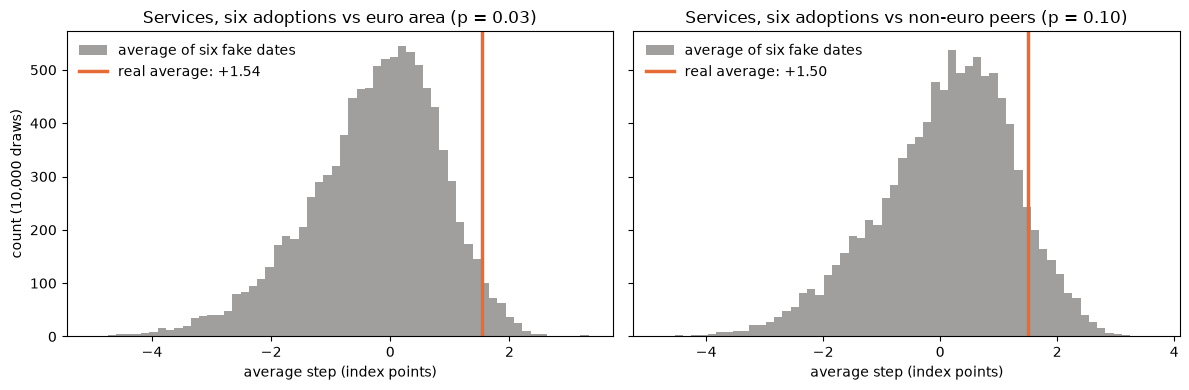

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, control in zip(axes, CONTROLS):
    real, draws = draws_for_plot[("SERV", control)]
    p = (1 + (draws >= real).sum()) / (1 + len(draws))
    ax.hist(draws, bins=60, color=GREY, label="average of six fake dates")
    ax.axvline(real, color=ORANGE, lw=2.5, label=f"real average: {real:+.2f}")
    ax.set_title(f"Services, six adoptions vs {NAMES[control]} (p = {p:.2f})")
    ax.set_xlabel("average step (index points)")
    ax.legend(frameon=False)
axes[0].set_ylabel("count (10,000 draws)")
fig.tight_layout()
fig.savefig(ROOT / "docs" / "img" / "placebo_services.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

- **Services: a real but modest effect across adoptions.** Averaged over the six adoptions, services rose
  about 1.5 points more than in the controls in the first year of the euro. That is larger than 97% of fake
  dates against the euro area (p ≈ 0.03) and 90% against the non-euro peers (p ≈ 0.10).
- **Goods and all items: nothing beyond the noise.** This is the pattern the rounding story predicts:
  price rounding shows up in cheap, frequently bought services, not in goods sold by large chains.
- **Croatia on its own: borderline.** +1.8 against the euro area (p ≈ 0.07), +0.3 against the peers (p ≈ 0.37).
  The direction matches the other adoptions, but one country's estimate is too noisy to pin down its size.

## Caveats

- **Overlapping windows.** Neighbouring fake dates share most of their data, so the ~40-220 fake estimates
  per adopter are far from independent; the p-values are a guide, not exact.
- **Fake dates include crises** (2008-10, EU accession, COVID). That is deliberate: the real adoptions also
  happened in eventful times (Croatia at the peak of the 2022 inflation surge), so the placebo noise should
  include such periods.
- **Slovenia has few fake dates** (38), because its 2007 adoption leaves little history before it.
- One trend window (24 months) is tested here; the Power BI report shows how the real estimates move with
  the window.